In [432]:
import warnings
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings('ignore')

In [375]:
df = pd.read_csv("income_evaluation.csv")

In [376]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [377]:
df.columns

Index(['age', ' workclass', ' fnlwgt', ' education', ' education-num',
       ' marital-status', ' occupation', ' relationship', ' race', ' sex',
       ' capital-gain', ' capital-loss', ' hours-per-week', ' native-country',
       ' income'],
      dtype='object')

In [378]:
col_names = ["age", "workclass", "finalweigth", "education", "education_num", "marital_status",
             "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"]

df.columns = col_names

In [379]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   finalweigth     32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [380]:
df.describe()

,age,finalweigth,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [381]:
df["income"].value_counts()

income
<=50K    24720
>50K      7841
Name: count, dtype: int64

In [382]:
categorical = [col for col in df.columns if df[col].dtype == 'O']
numerical = [col for col in df.columns if df[col].dtype != 'O']

In [383]:
for col in df[categorical]:
    print(f"{df[col].value_counts()} \ndata_sum_{col}: {df[col].value_counts().sum()} \n{"-"*30}")

workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
?                    1836
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64 
data_sum_workclass: 32561 
------------------------------
education
HS-grad         10501
Some-college     7291
Bachelors        5355
Masters          1723
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           646
Prof-school       576
9th               514
12th              433
Doctorate         413
5th-6th           333
1st-4th           168
Preschool          51
Name: count, dtype: int64 
data_sum_education: 32561 
------------------------------
marital_status
Married-civ-spouse       14976
Never-married            10683
Divorced                  4443
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse      

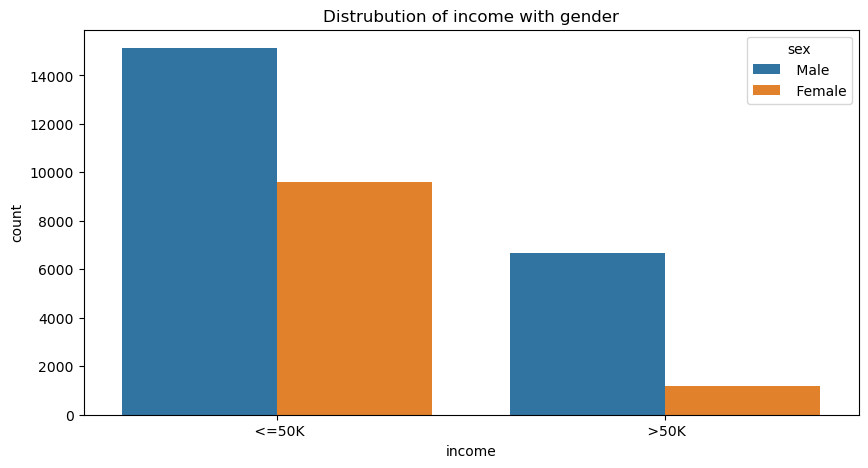

In [384]:
fig, ax = plt.subplots(figsize=(10,5))
ax = sns.countplot(data=df, x=df["income"], hue="sex")
plt.title("Distrubution of income with gender", fontsize=12)
plt.show()

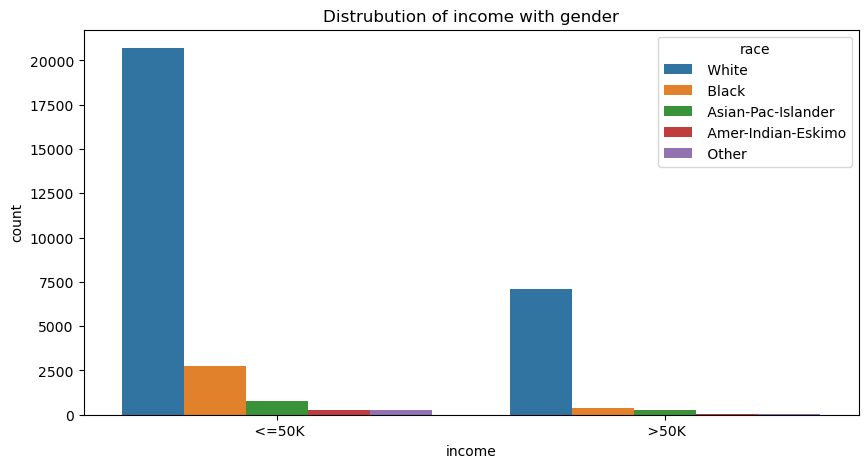

In [385]:
fig, ax = plt.subplots(figsize=(10,5))
ax = sns.countplot(data=df, x=df["income"], hue="race")
plt.title("Distrubution of income with gender", fontsize=12)
plt.show()

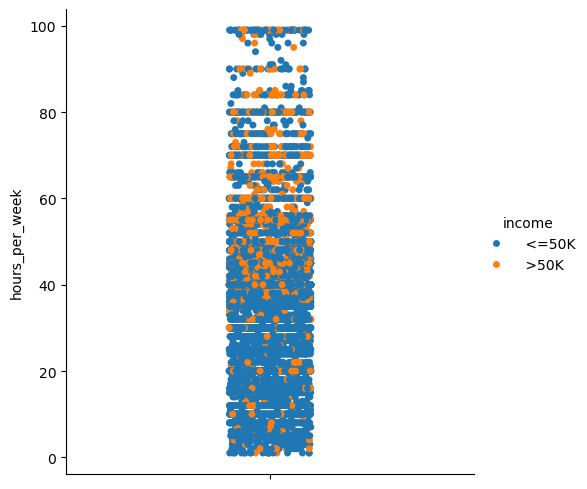

In [386]:
sns.catplot(y=df["hours_per_week"], hue=df["income"])
plt.show()

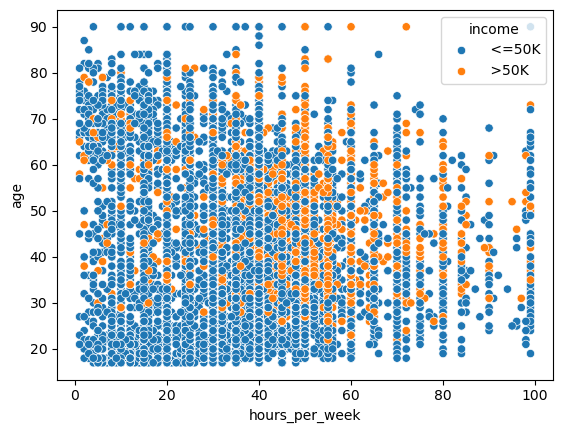

In [387]:
sns.scatterplot(x=df["hours_per_week"], y=df["age"], hue=df["income"])
plt.show()

In [388]:
over_40_hours = df[df["hours_per_week"] > 40]
under_40_hours = df[df["hours_per_week"] <= 40]

In [389]:
over_40_hours["income"].value_counts()

income
<=50K    5725
>50K     3856
Name: count, dtype: int64

In [390]:
3856 / (5725 + 3856)

0.4024632084333577

In [391]:
under_40_hours["income"].value_counts()

income
<=50K    18995
>50K      3985
Name: count, dtype: int64

In [392]:
3985 / (18995 + 3985)

0.17341166231505656

In [393]:
df["workclass"].unique()

array([' State-gov', ' Self-emp-not-inc', ' Private', ' Federal-gov',
       ' Local-gov', ' ?', ' Self-emp-inc', ' Without-pay',
       ' Never-worked'], dtype=object)

In [394]:
df["workclass"] = df["workclass"].replace(" ?", np.nan)
df["occupation"] = df["occupation"].replace(" ?", np.nan)
df["native_country"] = df["native_country"].replace(" ?", np.nan)

In [395]:
df.isnull().sum()

age                  0
workclass         1836
finalweigth          0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64

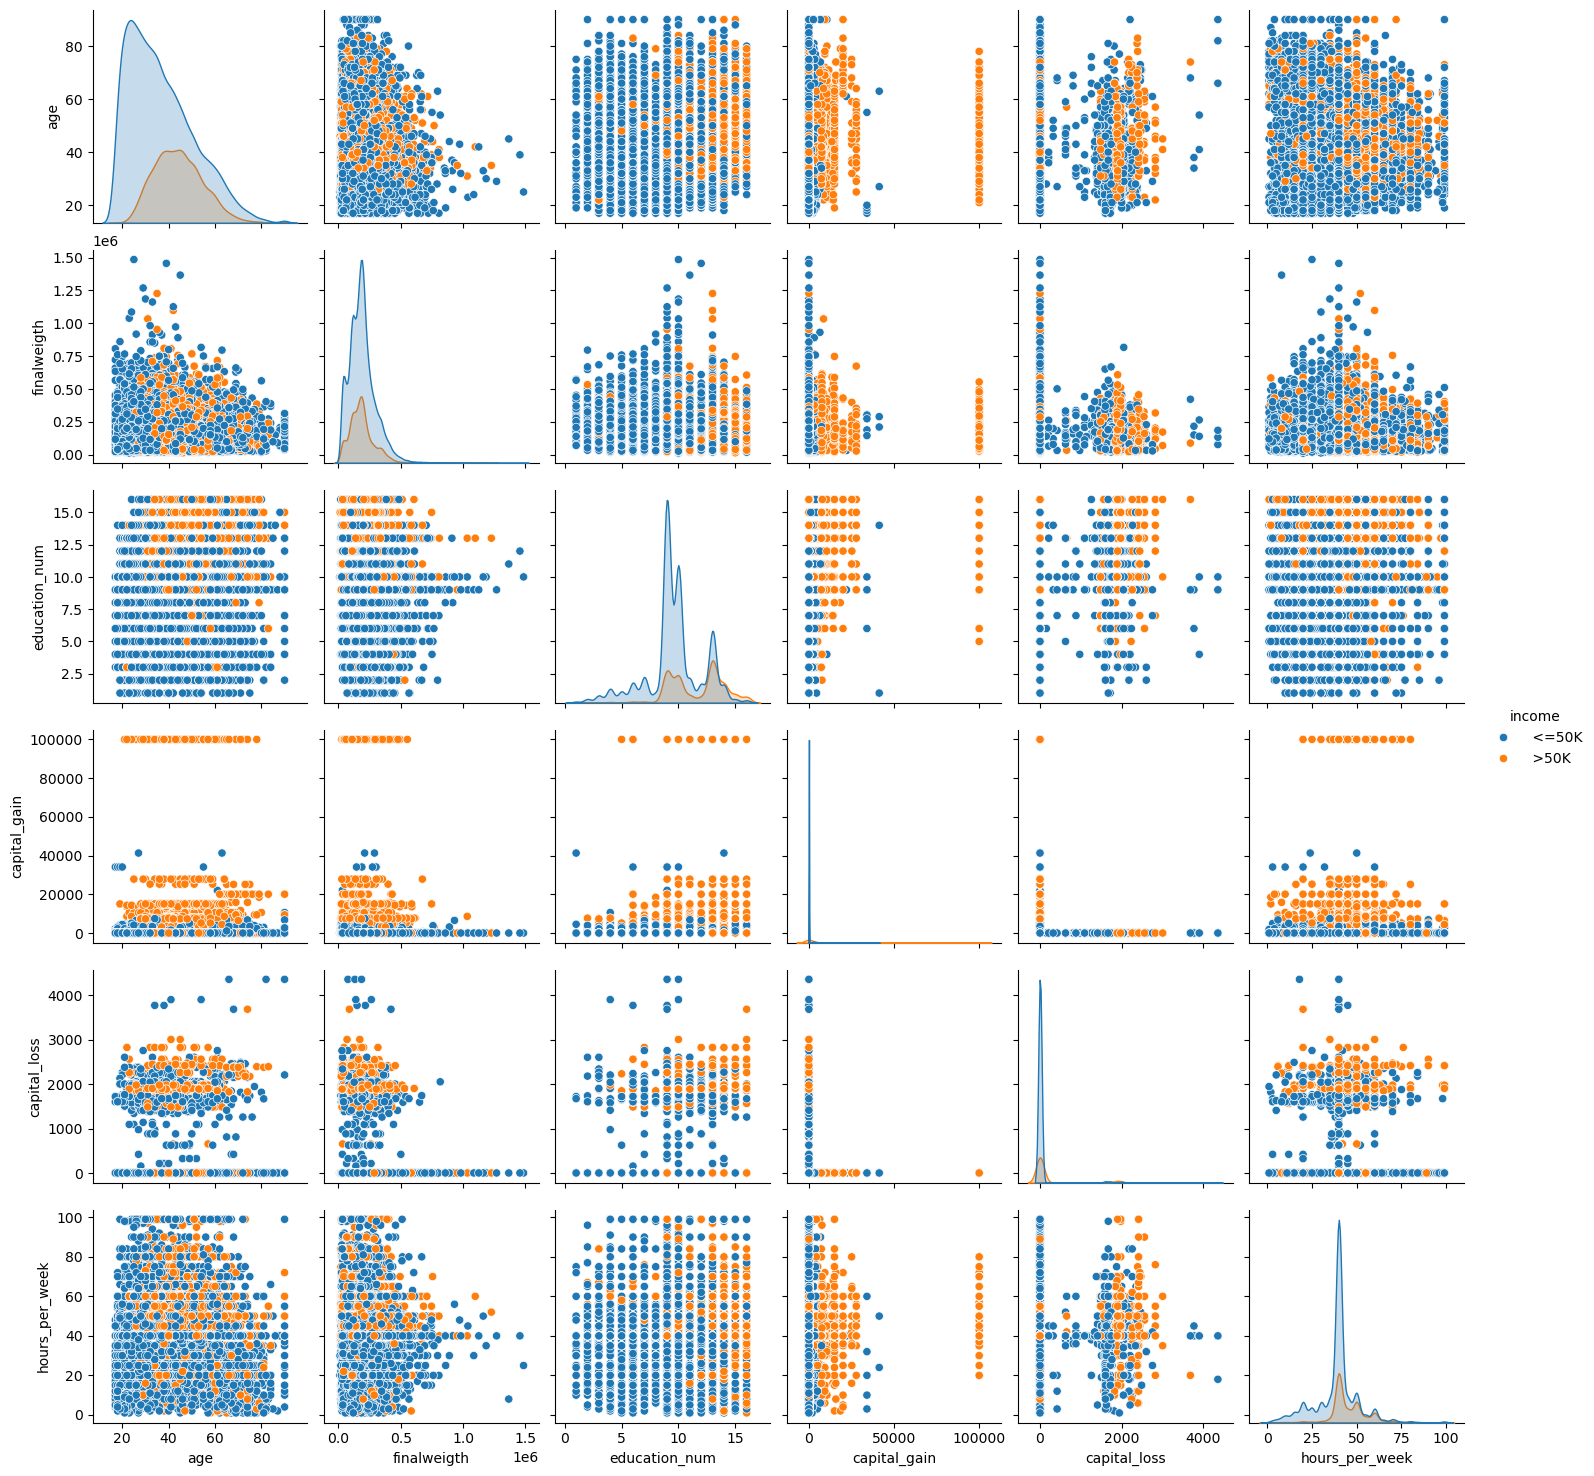

In [396]:
sns.pairplot(data=df, hue="income")
plt.show()

In [397]:
X = df.drop("income", axis=1)
y = df["income"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=15)

In [398]:
categorical = [col for col in X_train.columns if X_train[col].dtype == 'O']

In [399]:
X_train[categorical].isnull().sum()

workclass         1262
education            0
marital_status       0
occupation        1265
relationship         0
race                 0
sex                  0
native_country     392
dtype: int64

In [400]:
X_test[categorical].isnull().sum()

workclass         574
education           0
marital_status      0
occupation        578
relationship        0
race                0
sex                 0
native_country    191
dtype: int64

In [401]:
for i in [X_train, X_test]:
    i["workclass"] = i["workclass"].fillna(X_train["workclass"].mode()[0])
    i["occupation"] = i["occupation"].fillna(X_train["occupation"].mode()[0])
    i["native_country"] = i["native_country"].fillna(X_train["native_country"].mode()[0])

In [402]:
for col in categorical:
    X_train[col] = X_train[col].str.strip()
    X_test[col] = X_test[col].str.strip()

In [403]:
#encoding

In [404]:
X_train[categorical].head()

,workclass,education,marital_status,occupation,relationship,race,sex,native_country
32174,Self-emp-not-inc,Bachelors,Never-married,Sales,Not-in-family,White,Male,United-States
2680,Local-gov,Bachelors,Married-civ-spouse,Prof-specialty,Husband,White,Male,El-Salvador
10874,Private,Some-college,Widowed,Exec-managerial,Unmarried,White,Female,United-States
25028,Private,9th,Married-civ-spouse,Craft-repair,Husband,Other,Male,Mexico
25881,Self-emp-inc,Bachelors,Married-civ-spouse,Adm-clerical,Husband,White,Male,United-States


In [405]:
X_train[categorical].nunique()

workclass          8
education         16
marital_status     7
occupation        14
relationship       6
race               5
sex                2
native_country    40
dtype: int64

In [406]:
y_train.unique()

array([' <=50K', ' >50K'], dtype=object)

In [407]:
y_train_binary = y_train.apply(lambda x: 1 if x.strip() == '>50K' else 0)

In [408]:
target_means = y_train_binary.groupby(X_train["native_country"]).mean()

In [409]:
X_train["native_country_encoded"] = X_train["native_country"].map(target_means)
X_train["native_country_encoded"] = X_train["native_country_encoded"].fillna(y_train_binary.mean())

X_test["native_country_encoded"] = X_test["native_country"].map(target_means)
X_test["native_country_encoded"] = X_test["native_country_encoded"].fillna(y_train_binary.mean())

In [410]:
X_train.head()

,age,workclass,finalweigth,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,native_country_encoded
32174,44,Self-emp-not-inc,157217,Bachelors,13,Never-married,Sales,Not-in-family,White,Male,0,0,42,United-States,0.247311
2680,26,Local-gov,336969,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,28,El-Salvador,0.129032
10874,53,Private,233369,Some-college,10,Widowed,Exec-managerial,Unmarried,White,Female,0,0,40,United-States,0.247311
25028,30,Private,348618,9th,5,Married-civ-spouse,Craft-repair,Husband,Other,Male,0,0,40,Mexico,0.062907
25881,50,Self-emp-inc,140516,Bachelors,13,Married-civ-spouse,Adm-clerical,Husband,White,Male,0,0,40,United-States,0.247311


In [411]:
X_train = X_train.drop("native_country", axis=1)
X_test = X_test.drop("native_country", axis=1)

In [412]:
categorical

['workclass',
 'education',
 'marital_status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'native_country']

In [413]:
one_hot_categories = [
    "workclass",  
    "education",
    "marital_status",    
    "occupation",        
    "relationship",       
    "race",      
    "sex"          
]

In [414]:
preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown='ignore', sparse_output=False), one_hot_categories)],
        remainder="passthrough")            #handle_unknown -> bilinmeyen kolun varsa onu pass gecer
                                            #matrix olarak vermesin diye sparse_output=False yaptik numpy array olarak verdi.          

X_train_enc = preprocess.fit_transform(X_train)
X_test_enc = preprocess.transform(X_test)

In [415]:
columns = preprocess.get_feature_names_out()

In [416]:
X_train = pd.DataFrame(X_train_enc, columns=columns, index=X_train.index)
X_test = pd.DataFrame(X_test_enc, columns=columns, index=X_test.index)

In [417]:
X_train.head()

,cat__workclass_Federal-gov,cat__workclass_Local-gov,cat__workclass_Never-worked,cat__workclass_Private,cat__workclass_Self-emp-inc,cat__workclass_Self-emp-not-inc,cat__workclass_State-gov,cat__workclass_Without-pay,cat__education_10th,cat__education_11th,...,cat__race_White,cat__sex_Female,cat__sex_Male,remainder__age,remainder__finalweigth,remainder__education_num,remainder__capital_gain,remainder__capital_loss,remainder__hours_per_week,remainder__native_country_encoded
32174,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,44.0,157217.0,13.0,0.0,0.0,42.0,0.247311
2680,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,26.0,336969.0,13.0,0.0,0.0,28.0,0.129032
10874,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,53.0,233369.0,10.0,0.0,0.0,40.0,0.247311
25028,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,30.0,348618.0,5.0,0.0,0.0,40.0,0.062907
25881,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,50.0,140516.0,13.0,0.0,0.0,40.0,0.247311


In [418]:
cols = X_train.columns

In [419]:
from sklearn.preprocessing import RobustScaler # RandomForest icin gereksiz.

scaler = RobustScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [420]:
X_train = pd.DataFrame(X_train, columns=cols)
X_test = pd.DataFrame(X_test, columns=cols)

In [421]:
#training

In [422]:
rfc = RandomForestClassifier(n_estimators=10, random_state=15)

rfc.fit(X_train, y_train)
y_pred = rfc.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, y_pred))
print("-"*60)
print("Classification Report: \n", classification_report(y_test, y_pred))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

Accuracy Score:  0.8538233186610708
------------------------------------------------------------
Classification Report: 
               precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      7444
        >50K       0.74      0.60      0.66      2325

    accuracy                           0.85      9769
   macro avg       0.81      0.77      0.78      9769
weighted avg       0.85      0.85      0.85      9769

------------------------------------------------------------
Confusion Matrix: 
 [[6950  494]
 [ 934 1391]]


In [423]:
rfc = RandomForestClassifier(n_estimators=100, random_state=15)

rfc.fit(X_train, y_train)
y_pred = rfc.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, y_pred))
print("-"*60)
print("Classification Report: \n", classification_report(y_test, y_pred))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

Accuracy Score:  0.8629337700890573
------------------------------------------------------------
Classification Report: 
               precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      7444
        >50K       0.75      0.64      0.69      2325

    accuracy                           0.86      9769
   macro avg       0.82      0.79      0.80      9769
weighted avg       0.86      0.86      0.86      9769

------------------------------------------------------------
Confusion Matrix: 
 [[6931  513]
 [ 826 1499]]


In [424]:
feature_scores = pd.Series(rfc.feature_importances_, index=X_train.columns).sort_values(ascending=False)

In [425]:
feature_scores.tail(10)

cat__marital_status_Married-spouse-absent    0.000860
cat__education_12th                          0.000756
cat__education_5th-6th                       0.000620
cat__marital_status_Married-AF-spouse        0.000456
cat__education_1st-4th                       0.000247
cat__occupation_Priv-house-serv              0.000101
cat__education_Preschool                     0.000047
cat__workclass_Without-pay                   0.000016
cat__occupation_Armed-Forces                 0.000013
cat__workclass_Never-worked                  0.000000
dtype: float64

In [428]:
X_train = X_train.drop([
    "cat__marital_status_Married-spouse-absent",
    "cat__education_12th",
    "cat__education_5th-6th",
    "cat__marital_status_Married-AF-spouse",
    "cat__education_1st-4th",
    "cat__occupation_Priv-house-serv",
    "cat__education_Preschool",
    "cat__workclass_Without-pay",
    "cat__occupation_Armed-Forces",
    "cat__workclass_Never-worked",
    ], axis=1)

In [429]:
X_test = X_test.drop([
    "cat__marital_status_Married-spouse-absent",
    "cat__education_12th",
    "cat__education_5th-6th",
    "cat__marital_status_Married-AF-spouse",
    "cat__education_1st-4th",
    "cat__occupation_Priv-house-serv",
    "cat__education_Preschool",
    "cat__workclass_Without-pay",
    "cat__occupation_Armed-Forces",
    "cat__workclass_Never-worked",
    ], axis=1)

In [430]:
rfc = RandomForestClassifier(n_estimators=100, random_state=15)

rfc.fit(X_train, y_train)
y_pred = rfc.predict(X_test)

print("Accuracy Score: ", accuracy_score(y_test, y_pred))
print("-"*60)
print("Classification Report: \n", classification_report(y_test, y_pred))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred))

Accuracy Score:  0.8643668748080663
------------------------------------------------------------
Classification Report: 
               precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      7444
        >50K       0.75      0.65      0.69      2325

    accuracy                           0.86      9769
   macro avg       0.82      0.79      0.80      9769
weighted avg       0.86      0.86      0.86      9769

------------------------------------------------------------
Confusion Matrix: 
 [[6940  504]
 [ 821 1504]]


In [431]:
#hyperParameter Tuning

In [436]:
rf_params = ({
    "n_estimators" : [100, 200, 500, 1000],
    "criterion" : ["gini", "entropy", "log_loss"],
    "max_depth" : [5, 8, 10, 15, None],
    "max_features" : ["sqrt", "log2", 5, 6, 7, 8],
    "min_samples_split" : [2, 8, 15, 20]
})

In [438]:
rscv = RandomizedSearchCV(
    estimator=rfc,
    param_distributions=rf_params,
    cv=3,
    n_jobs=-1
)

rscv.fit(X_train, y_train)
y_pred_rscv = rscv.predict(X_test)

print("Best Parameters: ", rscv.best_params_)
print("-"*60)
print("Best Score: ", rscv.best_score_)
print("-"*60)
print("Accuracy Score: ", accuracy_score(y_test, y_pred_rscv))
print("-"*60)
print("Classification Report: \n", classification_report(y_test, y_pred_rscv))
print("-"*60)
print("Confusion Matrix: \n", confusion_matrix(y_test, y_pred_rscv))

Best Parameters:  {'n_estimators': 100, 'min_samples_split': 20, 'max_features': 7, 'max_depth': None, 'criterion': 'log_loss'}
------------------------------------------------------------
Best Score:  0.8604775216347585
------------------------------------------------------------
Accuracy Score:  0.8699969290613164
------------------------------------------------------------
Classification Report: 
               precision    recall  f1-score   support

       <=50K       0.90      0.94      0.92      7444
        >50K       0.77      0.65      0.70      2325

    accuracy                           0.87      9769
   macro avg       0.83      0.79      0.81      9769
weighted avg       0.87      0.87      0.87      9769

------------------------------------------------------------
Confusion Matrix: 
 [[6985  459]
 [ 811 1514]]
